# ML Zoomcamp 2026 — Homework 4: Evaluation
A commented, step-by-step notebook for predicting whether a lead converts (`converted = 1`).

We adapt the lesson's `DictVectorizer`, logistic regression, confusion counts, and `train`/`predict`/`KFold` workflow to the homework dataset. The homework settings take precedence over the churn example. 


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score, f1_score

# Record versions: numerical solvers can give slightly different results across environments.
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True, 'grid.alpha': 0.25})


Python: 3.14.2
NumPy: 2.5.4 | pandas: 3.0.6 | scikit-learn: 1.9.1


## 2. Load and inspect the data



In [2]:
DATA_URL = ('https://raw.githubusercontent.com/DataTalksClub/'
            'machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
DATA_PATH = Path('course_lead_scoring_2026.csv')

# A local copy lets subsequent runs work without an internet connection.
if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    df = pd.read_csv(DATA_URL)
    df.to_csv(DATA_PATH, index=False)

print('Rows and columns:', df.shape)
display(df.head())
display(df.dtypes.rename('dtype').to_frame())


Rows and columns: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


,dtype
lead_source,str
industry,str
employment_status,str
location,str
annual_income,float64
number_of_courses_viewed,int64
interaction_count,int64
lead_score,float64
converted,int64


In [3]:
# The target must NEVER be included in these lists: that would leak the answer.
target = 'converted'
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
features = categorical + numerical
assert set(df.columns) == set(features + [target]), 'Unexpected dataset columns.'
assert df[target].notna().all(), 'The target must not be missing.'
assert set(df[target].unique()) == {0, 1}, 'Expected a binary 0/1 target.'

# Inspect missing values BEFORE replacing them.
display(df[features].isna().sum().rename('missing_before').to_frame())

# categorical missing values become the string 'NA';
# numerical missing values become 0.0. These are constants, not learned statistics,
# so applying this before splitting does not learn anything from validation/test data.
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
assert not df[features].isna().any().any()
print('Missing feature values after filling:', df[features].isna().sum().sum())


,missing_before
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35


Missing feature values after filling: 0


## 3. Create the required train / validation / test split
The first split reserves 20% for testing. The second reserves 25% of the remaining 80%, which is 20% of the original data, for validation. That leaves 60% for training.

Use the exact calls in the homework. Adding stratification or changing the seed would change the rows and therefore the answers. Keep `df_full_train` in its original split order for cross-validation.


In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

# Resetting the index does not shuffle rows. It only gives them simple row labels.
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

# Keep the target in the dataframes for convenient fold creation later.
# Every model input explicitly selects `features`, which excludes the target.
y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()

print(f'Train: {len(df_train)}, validation: {len(df_val)}, test: {len(df_test)}')
print(f'Full training set for CV: {len(df_full_train)}')
assert len(df_train) + len(df_val) + len(df_test) == len(df)


Train: 3000, validation: 1000, test: 1000
Full training set for CV: 4000


## Question 1 — Which numerical feature ranks leads best?
ROC AUC measures ranking quality: roughly, how often a positive example receives a higher score than a negative example, with half credit for tied scores. A random ranking has AUC near 0.5; perfect ranking has AUC 1.

Here we do **not train a model**. We use each numerical column itself as the score, using training rows only. If its AUC is below 0.5, negate the scores and recompute. This reversal is only for this question; it does not modify the model's input columns. This is a univariate comparison, not causal importance or importance conditional on other features.


In [5]:
feature_results = []
for feature in numerical:
    scores = df_train[feature].to_numpy()
    raw_auc = roc_auc_score(y_train, scores)
    reverse = raw_auc < 0.5
    # A low raw AUC can mean lower values are associated with conversion.
    oriented_auc = roc_auc_score(y_train, -scores if reverse else scores)
    feature_results.append({
        'feature': feature, 'raw_auc': raw_auc,
        'negated': reverse, 'auc': oriented_auc,
    })

feature_auc = pd.DataFrame(feature_results).sort_values('auc', ascending=False)
display(feature_auc.reset_index(drop=True))
q1_answer = feature_auc.iloc[0]['feature']
print('Q1 — highest AUC:', q1_answer)


,feature,raw_auc,negated,auc
0,lead_score,0.788225,False,0.788225
1,interaction_count,0.764920,False,0.764920
2,number_of_courses_viewed,0.722989,False,0.722989
3,annual_income,0.608198,False,0.608198


Q1 — highest AUC: lead_score


## Question 2 — Train and evaluate logistic regression
`DictVectorizer` converts categorical strings into indicator columns (one-hot encoding) and keeps numerical values as numbers. Fit the encoder on training rows only, then reuse it on validation rows so the columns match.

Following the lesson, we use small `train` and `predict` helper functions. We set the solver, `C`, and iteration limit exactly as requested. No feature scaling or extra transformations are added. For AUC we need probabilities, not predictions already rounded to 0 or 1.


In [6]:
def train(frame, y, C=1.0):
    """Fit a fresh encoder and model using only the provided training rows."""
    train_dicts = frame[features].to_dict(orient='records')
    # Dense arrays match the lesson and are small enough for this dataset.
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(train_dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model


def predict(frame, dv, model):
    """Return P(converted=1) using an ALREADY fitted encoder and model."""
    dicts = frame[features].to_dict(orient='records')
    X = dv.transform(dicts)  # transform, not fit_transform: no refitting here!
    # With binary labels 0 and 1, column 1 is the probability of conversion.
    assert np.array_equal(model.classes_, [0, 1])
    return model.predict_proba(X)[:, 1]


dv, model = train(df_train, y_train, C=1.0)
y_pred = predict(df_val, dv, model)
val_auc = roc_auc_score(y_val, y_pred)
q2_answer = round(val_auc, 3)
print('Number of encoded features:', len(dv.get_feature_names_out()))
print(f'Validation ROC AUC: {val_auc:.6f}')
print(f'Q2 — rounded AUC: {q2_answer:.3f}')


Number of encoded features: 28
Validation ROC AUC: 0.731822
Q2 — rounded AUC: 0.732


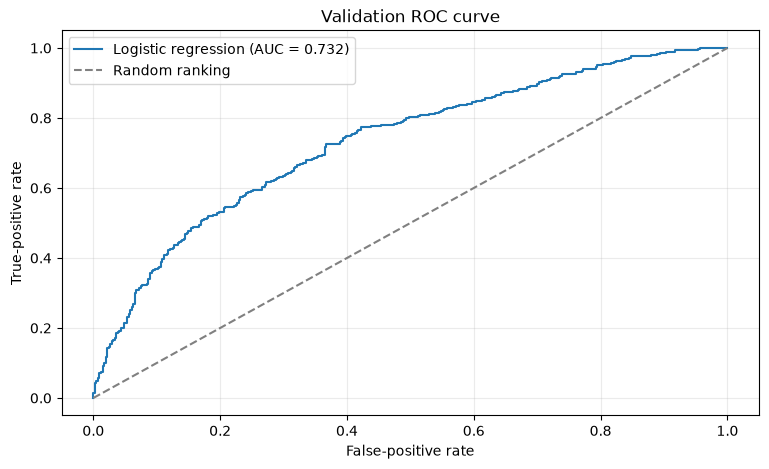

In [7]:
# Optional illustration: the ROC curve shows true-positive vs false-positive rate.
# The dashed diagonal represents a random ranking.
fpr, tpr, _ = roc_curve(y_val, y_pred)
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f'Logistic regression (AUC = {val_auc:.3f})')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
ax.set(xlabel='False-positive rate', ylabel='True-positive rate', title='Validation ROC curve')
ax.legend()
plt.show()


## Question 3 — Precision and recall across thresholds
A probability becomes a decision when we choose a threshold: predict conversion when `probability >= threshold`.

- **TP**: predicted conversion and actually converted.
- **FP**: predicted conversion but did not convert.
- **FN**: predicted no conversion but actually converted.
- **TN**: predicted no conversion and did not convert.

Precision = TP / (TP + FP): how many predicted conversions are correct? Recall = TP / (TP + FN): how many actual conversions do we find?

We compute all 101 thresholds, including 0 and 1. If a denominator is zero, use 0 for that metric. The homework defines the intersection as the smallest absolute precision–recall gap, excluding points where both are zero.


In [8]:
thresholds = np.linspace(0.0, 1.0, 101)
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)
rows = []

for threshold in thresholds:
    predicted_positive = (y_pred >= threshold)
    predicted_negative = ~predicted_positive
    # Boolean AND selects rows satisfying both conditions; sum counts those rows.
    tp = np.sum(predicted_positive & actual_positive)
    fp = np.sum(predicted_positive & actual_negative)
    fn = np.sum(predicted_negative & actual_positive)
    tn = np.sum(predicted_negative & actual_negative)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    rows.append([threshold, tp, fp, fn, tn, precision, recall])

metrics = pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall'])
metrics['gap'] = abs(metrics['precision'] - metrics['recall'])
valid = metrics.loc[(metrics['precision'] != 0) | (metrics['recall'] != 0)]
intersection = valid.loc[valid['gap'].idxmin()]
# idxmin picks the first (smallest) threshold if there is an exact tie.
q3_answer = float(intersection['threshold'])
display(intersection[['threshold', 'precision', 'recall', 'gap']].to_frame('value'))
print(f'Q3 — closest precision/recall threshold: {q3_answer:.2f}')


,value
threshold,0.630000
precision,0.732759
recall,0.725256
gap,0.007503


Q3 — closest precision/recall threshold: 0.63


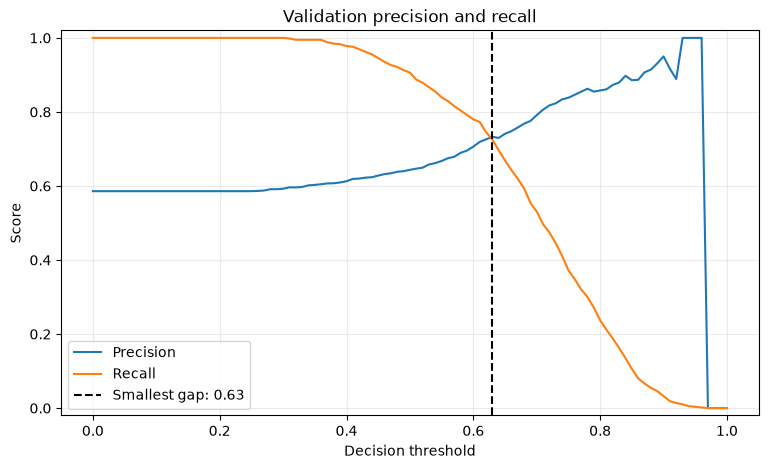

In [9]:
fig, ax = plt.subplots()
ax.plot(metrics['threshold'], metrics['precision'], label='Precision')
ax.plot(metrics['threshold'], metrics['recall'], label='Recall')
ax.axvline(q3_answer, color='black', linestyle='--', label=f'Smallest gap: {q3_answer:.2f}')
ax.set(xlabel='Decision threshold', ylabel='Score', ylim=(-0.02, 1.02),
       title='Validation precision and recall')
ax.legend()
plt.show()


## Question 4 — Find the threshold with the highest F1
F1 is the harmonic mean of precision and recall: **2 × precision × recall / (precision + recall)**. A high F1 requires both metrics to be reasonably high. When both are zero, define F1 as zero.

Use the same validation probabilities and the same threshold grid. We are changing decisions, not retraining the model. The best F1 threshold need not equal the precision–recall intersection.


,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616


Q4 — maximizing threshold (first if tied): 0.41


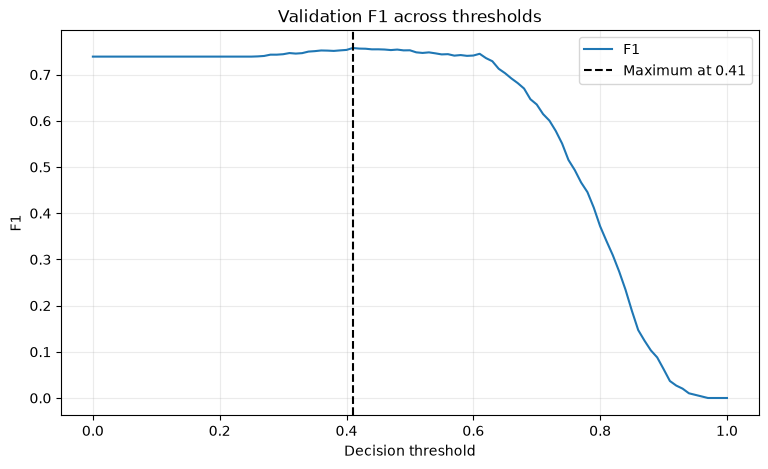

Manual precision, recall, and F1 agree with scikit-learn.


In [10]:
# np.divide with where avoids dividing by zero, even at extreme thresholds.
numerator = (2 * metrics['precision'] * metrics['recall']).to_numpy()
denominator = (metrics['precision'] + metrics['recall']).to_numpy()
metrics['f1'] = np.divide(numerator, denominator,
                          out=np.zeros_like(numerator), where=denominator != 0)

best_f1 = metrics['f1'].max()
# Display all exact maximizers rather than hiding a possible tie.
best_f1_rows = metrics.loc[metrics['f1'] == best_f1]
q4_answer = float(best_f1_rows.iloc[0]['threshold'])
display(best_f1_rows[['threshold', 'precision', 'recall', 'f1']])
print(f'Q4 — maximizing threshold (first if tied): {q4_answer:.2f}')

fig, ax = plt.subplots()
ax.plot(metrics['threshold'], metrics['f1'], label='F1')
ax.axvline(q4_answer, color='black', linestyle='--', label=f'Maximum at {q4_answer:.2f}')
ax.set(xlabel='Decision threshold', ylabel='F1', title='Validation F1 across thresholds')
ax.legend()
plt.show()

# Verify our hand-written formulas against scikit-learn at EVERY threshold.
for row in metrics.itertuples():
    labels = y_pred >= row.threshold
    assert np.isclose(row.precision, precision_score(y_val, labels, zero_division=0))
    assert np.isclose(row.recall, recall_score(y_val, labels, zero_division=0))
    assert np.isclose(row.f1, f1_score(y_val, labels, zero_division=0))
print('Manual precision, recall, and F1 agree with scikit-learn.')


## Question 5 — Measure variability using 5-fold cross-validation
One validation split may be unusually easy or difficult. Cross-validation rotates which rows are held out. For each fold, train on four fifths of `df_full_train` and evaluate on the remaining fifth. Every row is validation data once.

Use `KFold`, as requested, and create a fresh encoder and model inside each fold. This prevents the encoder from learning validation categories during fitting. `.iloc` selects by position because `KFold` returns positional indices.

We use NumPy's population standard deviation (`ddof=0`), matching the course. Pandas' default `.std()` uses `ddof=1` and would give a different value.


In [11]:
def cross_validate(C):
    """Return the five validation AUC scores for one C value."""
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for fold_number, (train_idx, val_idx) in enumerate(kfold.split(df_full_train), start=1):
        # Separate names preserve the original holdout data and model from Q2–Q4.
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]
        fold_y_train = fold_train[target].to_numpy()
        fold_y_val = fold_val[target].to_numpy()
        fold_dv, fold_model = train(fold_train, fold_y_train, C=C)
        fold_pred = predict(fold_val, fold_dv, fold_model)
        fold_auc = roc_auc_score(fold_y_val, fold_pred)
        scores.append(fold_auc)
        print(f'C={C:g}, fold={fold_number}, AUC={fold_auc:.6f}')
    return np.array(scores)

cv_scores = cross_validate(C=1.0)
cv_mean = np.mean(cv_scores)
cv_std = np.std(cv_scores, ddof=0)
q5_answer = round(float(cv_std), 3)
print(f'Mean AUC: {cv_mean:.6f}; standard deviation: {cv_std:.6f}')
print(f'Q5 — standard deviation to 3 decimals: {q5_answer:.3f}')


C=1, fold=1, AUC=0.730560
C=1, fold=2, AUC=0.729573
C=1, fold=3, AUC=0.736343
C=1, fold=4, AUC=0.741245
C=1, fold=5, AUC=0.720914
Mean AUC: 0.731727; standard deviation: 0.006853
Q5 — standard deviation to 3 decimals: 0.007


## Question 6 — Choose the regularization parameter C
`C` controls inverse regularization strength: a smaller value penalizes large coefficients more strongly. Compare the requested values using the same folds for a fair comparison.

Round the mean and standard deviation to three decimals, then rank by highest rounded mean, lowest rounded standard deviation, and finally smallest C, following the assignment's tie-breaking rule. Keep unrounded values visible for inspection.


In [12]:
C_values = [0.000001, 0.001, 1]
tuning_rows = []
for C in C_values:
    # Reuse Q5's scores for C=1: the data, folds, and settings are identical.
    scores = cv_scores if C == 1 else cross_validate(C=C)
    tuning_rows.append({'C': C, 'mean_auc': np.mean(scores),
                        'std_auc': np.std(scores, ddof=0)})

tuning = pd.DataFrame(tuning_rows)
tuning['mean_rounded'] = tuning['mean_auc'].round(3)
tuning['std_rounded'] = tuning['std_auc'].round(3)
ranked = tuning.sort_values(['mean_rounded', 'std_rounded', 'C'],
                            ascending=[False, True, True])
q6_answer = float(ranked.iloc[0]['C'])
display(ranked.reset_index(drop=True))
print(f'Q6 — selected C: {q6_answer:g}')


C=1e-06, fold=1, AUC=0.594100
C=1e-06, fold=2, AUC=0.640214
C=1e-06, fold=3, AUC=0.600157
C=1e-06, fold=4, AUC=0.636447
C=1e-06, fold=5, AUC=0.612753
C=0.001, fold=1, AUC=0.750435
C=0.001, fold=2, AUC=0.747533
C=0.001, fold=3, AUC=0.758354
C=0.001, fold=4, AUC=0.758413
C=0.001, fold=5, AUC=0.731126


,C,mean_auc,std_auc,mean_rounded,std_rounded
0,0.001000,0.749172,0.009996,0.749,0.010
1,1.000000,0.731727,0.006853,0.732,0.007
2,0.000001,0.616734,0.018670,0.617,0.019


Q6 — selected C: 0.001


## Computed answers
This table is generated from the calculations above. It does not force results toward the multiple-choice options. If your calculated result does not match an option at the requested precision, check the dataset, split settings, preprocessing, and package versions before submitting.

The validation data was used to select thresholds and hyperparameters, so these are development results. Keep the test set untouched until all choices are fixed. AUC describes ranking; F1, precision, and recall describe decisions at a chosen threshold.


In [13]:
answers = pd.DataFrame({
    'Question': ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6'],
    'Result': [q1_answer, f'{q2_answer:.3f}', f'{q3_answer:.2f}',
               f'{q4_answer:.2f}', f'{q5_answer:.3f}', f'{q6_answer:g}'],
    'Meaning': ['Highest numerical-feature AUC', 'Validation ROC AUC',
                'Smallest precision–recall gap threshold', 'Maximum F1 threshold',
                'Five-fold AUC standard deviation', 'Best C under the tie rules'],
})
display(answers)


,Question,Result,Meaning
0,Q1,lead_score,Highest numerical-feature AUC
1,Q2,0.732,Validation ROC AUC
2,Q3,0.63,Smallest precision–recall gap threshold
3,Q4,0.41,Maximum F1 threshold
4,Q5,0.007,Five-fold AUC standard deviation
5,Q6,0.001,Best C under the tie rules
